# Day 25 / 100 — MachineAnomaly · Final Kaggle Research Notebook
### Hydraulic component condition + IMS bearing degradation monitoring

**Research notebook · Kaggle · two independent experiments**

- **UCI Hydraulic**: 2,205 cycles, supervised condition labels in `profile.txt`; healthy-reference anomaly detection, multi-component classification, chronological holdout.
- **NASA/IMS Bearings**: vibration snapshots across 3 run-to-failure tests; derive *unsupervised* health indicators from early-life references. **No fabricated frame-by-frame fault labels or accuracy.**
- Separate metrics, feature spaces, models and reports. All results must come from execution.
- Sources: [UCI hydraulic (CC BY 4.0)](https://archive.ics.uci.edu/dataset/447/condition+monitoring+of+hydraulic+systems), [NASA IMS](https://data.nasa.gov/dataset/ims-bearings).

**Kaggle input:** `/kaggle/input/datasets/wafabila/machineanomaly-dataset` (adjust only `INPUT_ROOT` if Kaggle mounts a different path).

**Scientific limits:** these two datasets are from different experimental rigs; they cannot be row-concatenated. Cross-domain scores cannot be directly compared. Hydraulic conditions are *component statuses*, not machine failure-event timestamps. IMS run-to-failure is used for trend illustration, not an officially labeled per-snapshot failure classifier.

## 00 · Configuration / environment

In [1]:
from __future__ import annotations
import os, sys, re, json, time, hashlib, zipfile, warnings, platform, traceback
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, balanced_accuracy_score, f1_score,
                             precision_recall_curve, ConfusionMatrixDisplay)
import joblib

SEED = 42
np.random.seed(SEED)
INPUT_ROOT = Path('/kaggle/input/datasets/wafabila/machineanomaly-dataset')
OUT = Path('/kaggle/working/machineanomaly_day25')
for p in [OUT, OUT/'reports',OUT/'plots',OUT/'models',OUT/'features',OUT/'examples']:
    p.mkdir(parents=True,exist_ok=True)
REPORT, PLOTS, MODELS, FEATURES = (OUT/x for x in ['reports','plots','models','features'])
CFG = {
 'run_hydraulic': True,
 'run_ims': True,
 'hydraulic_test_fraction': 0.20,
 'hydraulic_reference_train_fraction': 0.60,
 'iforest_estimators': 240,
 'ims_read_rows_per_snapshot': 4096, # representative start of each 1-s snapshot; NOT full-spectrum processing
 'ims_max_files_per_test': None, # None => every file; set positive integer only for a smoke test
 'ims_early_reference_fraction': .25,
 'ims_contamination': 0.03,
 'zip_include_features': True,
}
print('Input:',INPUT_ROOT,'exists?',INPUT_ROOT.exists())
print('Python',sys.version.split()[0], 'scikit-learn',__import__('sklearn').__version__)
if not INPUT_ROOT.is_dir():
 print('Visible mounts:', [str(x) for x in Path('/kaggle/input').iterdir()] if Path('/kaggle/input').exists() else [])
 raise FileNotFoundError(f'Attach dataset, or change INPUT_ROOT: {INPUT_ROOT}')
(REPORT/'run_config.json').write_text(json.dumps({'seed':SEED,'cfg':CFG,'input':str(INPUT_ROOT),'python':sys.version},indent=2))

Input: /kaggle/input/datasets/wafabila/machineanomaly-dataset exists? True
Python 3.13.15 scikit-learn 1.6.1


511

## 01 · Dataset inventory & source provenance

In [2]:
def sample_tree(root, depth=3, max_items=80):
    entries=[]
    for p in sorted(root.rglob('*')):
        try: relative=p.relative_to(root)
        except ValueError:continue
        if len(relative.parts)>depth:continue
        entries.append({'path':str(relative),'type':'dir' if p.is_dir() else 'file','bytes':int(p.stat().st_size) if p.is_file() else 0})
        if len(entries)>=max_items: break
    return pd.DataFrame(entries)
print('Mounted tree sample:')
display(sample_tree(INPUT_ROOT))
provenance=pd.DataFrame([
 {'source':'UCI Hydraulic Condition Monitoring','original_url':'https://archive.ics.uci.edu/dataset/447/condition+monitoring+of+hydraulic+systems','doi':'10.24432/C5CW21','license':'CC BY 4.0','role':'Supervised condition diagnosis and normal-reference anomaly benchmark','label_contract':'profile.txt: cooler/valve/pump/accumulator/stable flag'},
 {'source':'NASA IMS Bearings (University of Cincinnati)','original_url':'https://data.nasa.gov/dataset/ims-bearings','doi':'','license':'NASA portal: check original terms and attribution','role':'Three run-to-failure vibration trend / unsupervised anomaly monitoring','label_contract':'No per-snapshot fault classes; test-end damage descriptions only'}
])
provenance.to_csv(REPORT/'dataset_provenance.csv',index=False)
display(provenance)

Mounted tree sample:


,path,type,bytes
0,hydraulic-systems,dir,0
1,hydraulic-systems/CE.txt,file,911516
2,hydraulic-systems/CP.txt,file,779343
3,hydraulic-systems/EPS1.txt,file,87411594
4,hydraulic-systems/FS1.txt,file,7581926
5,hydraulic-systems/FS2.txt,file,8271923
6,hydraulic-systems/PS1.txt,file,91391892
7,hydraulic-systems/PS2.txt,file,82373611
8,hydraulic-systems/PS3.txt,file,69916801
9,hydraulic-systems/PS4.txt,file,46698180


,source,original_url,doi,license,role,label_contract
0,UCI Hydraulic Condition Monitoring,https://archive.ics.uci.edu/dataset/447/condit...,10.24432/C5CW21,CC BY 4.0,Supervised condition diagnosis and normal-refe...,profile.txt: cooler/valve/pump/accumulator/sta...
1,NASA IMS Bearings (University of Cincinnati),https://data.nasa.gov/dataset/ims-bearings,,NASA portal: check original terms and attribution,Three run-to-failure vibration trend / unsuper...,No per-snapshot fault classes; test-end damage...


## 02 · Resolve actual paths (nested Kaggle structure supported)

In [3]:
def find_hydraulic(root):
    paths=sorted((p for p in root.rglob('profile.txt') if p.is_file()),key=lambda p:len(p.parts))
    choices=[p.parent for p in paths if (p.parent/'PS1.txt').is_file() and (p.parent/'VS1.txt').is_file()]
    if len(choices)!=1:raise RuntimeError(f'Expected one hydraulic folder with PS1.txt, VS1.txt and profile.txt, found: {choices}')
    return choices[0]

def find_ims(root):
    matches={}
    for name in ('1st_test','2nd_test','3rd_test'):
        found=sorted((p for p in root.rglob(name) if p.is_dir()),key=lambda x:len(x.parts))
        if not found:raise FileNotFoundError(f'IMS {name} missing. Inspect Kaggle dataset input tree.')
        # One root per name; avoid choosing an empty redundant wrapper.
        matches[name]=next((p for p in found if any(x.is_file() for x in p.rglob('*'))),found[0])
    return matches
HYD_ROOT = find_hydraulic(INPUT_ROOT) if CFG['run_hydraulic'] else None
IMS_ROOTS = find_ims(INPUT_ROOT) if CFG['run_ims'] else {}
print('Hydraulic:',HYD_ROOT)
for key,root in IMS_ROOTS.items():print('IMS',key,':',root)
(REPORT/'resolved_paths.json').write_text(json.dumps({'hydraulic':str(HYD_ROOT),'ims':{k:str(v) for k,v in IMS_ROOTS.items()}},indent=2))

Hydraulic: /kaggle/input/datasets/wafabila/machineanomaly-dataset/hydraulic-systems
IMS 1st_test : /kaggle/input/datasets/wafabila/machineanomaly-dataset/ims-bearings/sensor-data/1st_test
IMS 2nd_test : /kaggle/input/datasets/wafabila/machineanomaly-dataset/ims-bearings/sensor-data/2nd_test
IMS 3rd_test : /kaggle/input/datasets/wafabila/machineanomaly-dataset/ims-bearings/sensor-data/3rd_test


432

## 03 · Hydraulic: load profile and validate ontology

In [4]:
if CFG['run_hydraulic']:
    target_names=['cooler','valve','pump','accumulator','stable_flag']
    profile=pd.read_csv(HYD_ROOT/'profile.txt',sep=r'\s+',header=None,engine='c')
    if profile.shape[1]!=5:raise ValueError(f'profile.txt must have 5 columns, found {profile.shape[1]}')
    profile.columns=target_names
    profile=profile.apply(pd.to_numeric,errors='raise')
    print('Cycles:',len(profile),'target distributions:')
    for col in profile:print(col,profile[col].value_counts(dropna=False).sort_index().to_dict())
    if not set(profile.stable_flag.unique()).issubset({0,1}): raise ValueError('Unexpected stability flag values')
    # 0 means not stable; 1 means stable under UCI profile convention.
    stable=profile.stable_flag.eq(1)
    healthy=(profile.cooler.eq(100)&profile.valve.eq(100)&profile.pump.eq(0)&profile.accumulator.eq(130))
    profile['component_healthy']=healthy.astype(int)
    profile['any_component_degraded']=(~healthy).astype(int)
    profile['eligible_stable']=stable.astype(int)
    display(profile.head())
    profile.to_csv(FEATURES/'hydraulic_profile.csv',index_label='cycle_id')
else:print('Hydraulic skipped')

Cycles: 2205 target distributions:
cooler {3: 732, 20: 732, 100: 741}
valve {73: 360, 80: 360, 90: 360, 100: 1125}
pump {0: 1221, 1: 492, 2: 492}
accumulator {90: 808, 100: 399, 115: 399, 130: 599}
stable_flag {0: 1449, 1: 756}


,cooler,valve,pump,accumulator,stable_flag,component_healthy,any_component_degraded,eligible_stable
0,3,100,0,130,1,0,1,1
1,3,100,0,130,1,0,1,1
2,3,100,0,130,1,0,1,1
3,3,100,0,130,1,0,1,1
4,3,100,0,130,1,0,1,1


## 04 · Hydraulic: sensor feature engineering — each cycle stays intact

In [5]:
SENSOR_NAMES=['PS1','PS2','PS3','PS4','PS5','PS6','EPS1','FS1','FS2','TS1','TS2','TS3','TS4','VS1','CE','CP','SE']

def matrix_features(path,n_cycles):
    # Load ONE sensor at a time. Entire 2205x6000 matrix is manageable in float32.
    data=pd.read_csv(path,sep=r'\s+',header=None,dtype=np.float32,engine='c').to_numpy(dtype=np.float32)
    if data.ndim!=2 or data.shape[0]!=n_cycles:raise ValueError(f'{path.name}: expected {n_cycles} cycles, got {data.shape}')
    if not np.isfinite(data).all(): raise ValueError(f'Non-finite values in {path.name}')
    delta=np.diff(data,axis=1)
    return np.stack([data.mean(axis=1), data.std(axis=1),data.min(axis=1),data.max(axis=1),
                     np.percentile(data,25,axis=1),np.percentile(data,50,axis=1),np.percentile(data,75,axis=1),
                     np.sqrt(np.mean(data**2,axis=1)),np.mean(np.abs(delta),axis=1),
                     np.std(delta,axis=1)],axis=1)

if CFG['run_hydraulic']:
    columns=['mean','std','min','max','q25','median','q75','rms','mean_abs_change','std_change']
    sensor_parts=[]; shapes={}
    for name in SENSOR_NAMES:
        path=HYD_ROOT/f'{name}.txt'
        if not path.is_file():raise FileNotFoundError(f'Missing UCI sensor {name}.txt')
        part=matrix_features(path,len(profile));shapes[name]=list(part.shape)
        sensor_parts.append(pd.DataFrame(part,columns=[f'{name}_{s}' for s in columns]))
        print('Processed',name,part.shape)
    X_h=pd.concat(sensor_parts,axis=1)
    if X_h.shape[0]!=len(profile) or X_h.isna().any().any():raise RuntimeError('Bad hydraulic features')
    X_h.to_csv(FEATURES/'hydraulic_cycle_features.csv',index_label='cycle_id')
    (REPORT/'hydraulic_feature_schema.json').write_text(json.dumps({'sensors':SENSOR_NAMES,'stats':columns,'shape':list(X_h.shape),'sensor_matrices':shapes},indent=2))
    print('Feature matrix:',X_h.shape)
else:print('Hydraulic skipped')

Processed PS1 (2205, 10)
Processed PS2 (2205, 10)
Processed PS3 (2205, 10)
Processed PS4 (2205, 10)
Processed PS5 (2205, 10)
Processed PS6 (2205, 10)
Processed EPS1 (2205, 10)
Processed FS1 (2205, 10)
Processed FS2 (2205, 10)
Processed TS1 (2205, 10)
Processed TS2 (2205, 10)
Processed TS3 (2205, 10)
Processed TS4 (2205, 10)
Processed VS1 (2205, 10)
Processed CE (2205, 10)
Processed CP (2205, 10)
Processed SE (2205, 10)
Feature matrix: (2205, 170)


## 05 · Hydraulic: time-ordered holdout, baseline, leakage checks

In [6]:
if CFG['run_hydraulic']:
    # Chronological split avoids mixing adjacent cycles into train/test.
    # Condition batches can still confound chronological extrapolation: report support.
    N=len(profile);cut=int(N*(1-CFG['hydraulic_test_fraction']))
    ix_train=np.arange(cut);ix_test=np.arange(cut,N)
    if len(ix_train)==0 or len(ix_test)==0:raise RuntimeError('Empty train/test')
    Xtr=X_h.iloc[ix_train];Xte=X_h.iloc[ix_test]
    stable_train=(profile.iloc[ix_train].stable_flag.to_numpy()==1)
    normal_train=(profile.iloc[ix_train].component_healthy.to_numpy()==1)&stable_train
    print('Train/test:',len(ix_train),len(ix_test),'Normal stable reference cycles:',int(normal_train.sum()))
    reference_policy='jointly_healthy_and_stable'
    if normal_train.sum()<30:
        # Jointly healthy status may be absent because operating conditions were varied separately.
        # Select least-degraded, stable cycles as a PROXY baseline using TRAIN data only.
        tr_prof=profile.iloc[ix_train]
        severity=(tr_prof.cooler.ne(100).astype(int)+tr_prof.valve.ne(100).astype(int)+
                  tr_prof.pump.ne(0).astype(int)+tr_prof.accumulator.ne(130).astype(int)).to_numpy()
        stable_ix=np.flatnonzero(stable_train)
        if len(stable_ix)<30:raise RuntimeError('Fewer than 30 stable training cycles; cannot fit reference model.')
        chosen_level=min(v for v in np.unique(severity[stable_ix]) if (severity[stable_ix]<=v).sum()>=30)
        normal_train=stable_train & (severity<=chosen_level)
        reference_policy=f'least_degraded_stable_training_proxy_max_degraded_components_{chosen_level}'
        print('WARNING: no adequate jointly healthy subset. Using explicit TRAIN-ONLY PROXY reference:',reference_policy)
    support=[]
    for t in ['cooler','valve','pump','accumulator','any_component_degraded']:
        support.append({'target':t,'train':profile.iloc[ix_train][t].value_counts().to_dict(),'test':profile.iloc[ix_test][t].value_counts().to_dict()})
    print('Split target support:');display(pd.DataFrame(support))
    (REPORT/'hydraulic_split_support.json').write_text(json.dumps({'cut':cut,'train_cycle_range':[0,cut-1],'test_cycle_range':[cut,N-1],'targets':support,'normal_reference_count':int(normal_train.sum()),'reference_policy':reference_policy},indent=2))
else:print('Hydraulic skipped')

Train/test: 1764 441 Normal stable reference cycles: 11
Split target support:


,target,train,test
0,cooler,"{3: 732, 20: 732, 100: 300}",{100: 441}
1,valve,"{100: 977, 73: 267, 80: 260, 90: 260}","{100: 148, 80: 100, 90: 100, 73: 93}"
2,pump,"{0: 1026, 2: 369, 1: 369}","{0: 195, 2: 123, 1: 123}"
3,accumulator,"{90: 666, 130: 566, 115: 266, 100: 266}","{90: 142, 115: 133, 100: 133, 130: 33}"
4,any_component_degraded,"{1: 1753, 0: 11}","{1: 431, 0: 10}"


## 06 · Hydraulic: healthy-reference Isolation Forest & real holdout metrics

,n,positives,negatives,roc_auc,average_precision,status,threshold,threshold_source,reference_policy,pred_positive,prediction_precision,note
0,441,431,10,0.578422,0.987459,ok,0.57579,95th percentile TRAIN reference only,least_degraded_stable_training_proxy_max_degra...,213,1.0,Weak anomaly proxy: any component degraded. St...


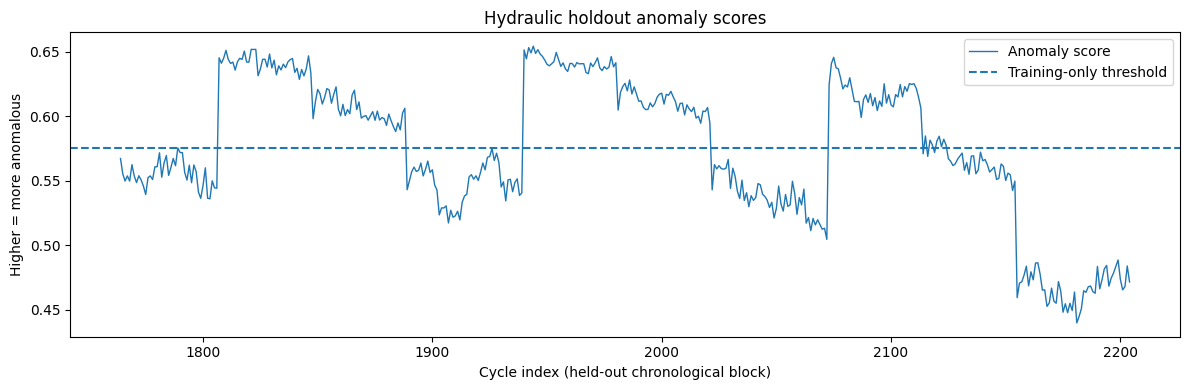

In [7]:
def binary_metrics(y_true,scores):
    y_true=np.asarray(y_true,dtype=int);scores=np.asarray(scores,dtype=float)
    result={'n':len(y_true),'positives':int(y_true.sum()),'negatives':int((y_true==0).sum())}
    if len(np.unique(y_true))<2:
        result.update({'roc_auc':None,'average_precision':None,'status':'not_estimable_single_class_test'})
    else:
        result.update({'roc_auc':float(roc_auc_score(y_true,scores)),
                       'average_precision':float(average_precision_score(y_true,scores)),'status':'ok'})
    return result
if CFG['run_hydraulic']:
    h_imp=SimpleImputer(strategy='median');h_scaler=StandardScaler()
    X_normal=h_scaler.fit_transform(h_imp.fit_transform(Xtr.iloc[np.flatnonzero(normal_train)]))
    h_iso=IsolationForest(n_estimators=CFG['iforest_estimators'],contamination='auto',random_state=SEED,n_jobs=-1)
    h_iso.fit(X_normal)
    train_scores=-h_iso.score_samples(X_normal)
    test_scores=-h_iso.score_samples(h_scaler.transform(h_imp.transform(Xte)))
    threshold=float(np.quantile(train_scores,.95)) # fixed before looking at test labels
    h_pred=(test_scores>=threshold).astype(int)
    y_test=profile.iloc[ix_test].any_component_degraded.to_numpy(dtype=int)
    h_eval=binary_metrics(y_test,test_scores)
    h_eval.update({'threshold':threshold,'threshold_source':'95th percentile TRAIN reference only','reference_policy':reference_policy,
                   'pred_positive':int(h_pred.sum()),'prediction_precision':float((h_pred[y_test==1].sum()/max(h_pred.sum(),1))) if h_pred.sum() else None,
                   'note':'Weak anomaly proxy: any component degraded. Stability and chronological drift can confound scores.'})
    display(pd.DataFrame([h_eval]));(REPORT/'hydraulic_iforest_metrics.json').write_text(json.dumps(h_eval,indent=2))
    pd.DataFrame({'cycle':ix_test,'anomaly_score':test_scores,'flag':h_pred,'known_any_degraded':y_test}).to_csv(REPORT/'hydraulic_holdout_predictions.csv',index=False)
    joblib.dump({'imputer':h_imp,'scaler':h_scaler,'model':h_iso,'threshold':threshold,'feature_columns':list(X_h.columns)},MODELS/'hydraulic_anomaly_iforest.joblib')
    fig,ax=plt.subplots(figsize=(12,4));ax.plot(ix_test,test_scores,lw=1,label='Anomaly score');ax.axhline(threshold,ls='--',label='Training-only threshold')
    ax.set(xlabel='Cycle index (held-out chronological block)',ylabel='Higher = more anomalous',title='Hydraulic holdout anomaly scores')
    ax.legend();fig.tight_layout();fig.savefig(PLOTS/'hydraulic_anomaly_timeline.png',dpi=150);plt.show()
else:print('Hydraulic skipped')

## 07 · Hydraulic: supervised component diagnostic baselines (separate from anomaly task)

In [8]:
if CFG['run_hydraulic']:
    comp_reports=[];comp_predictions=pd.DataFrame({'cycle':ix_test})
    for target in ['cooler','valve','pump','accumulator']:
        yt=profile.iloc[ix_train][target].to_numpy();yv=profile.iloc[ix_test][target].to_numpy()
        if len(np.unique(yt))<2:
            comp_reports.append({'target':target,'status':'skipped_single_class_train','train_classes':list(map(int,np.unique(yt)))})
            continue
        pipe=Pipeline([('imputer',SimpleImputer(strategy='median')),('forest',RandomForestClassifier(n_estimators=240,min_samples_leaf=2,class_weight='balanced_subsample',n_jobs=-1,random_state=SEED))])
        pipe.fit(Xtr,yt);yp=pipe.predict(Xte)
        unseen=sorted(set(yv)-set(yt));report={'target':target,'train_count':len(yt),'test_count':len(yv),
            'train_classes':sorted(map(int,np.unique(yt))),'test_classes':sorted(map(int,np.unique(yv))),
            'unseen_test_classes':sorted(map(int,unseen)), 'accuracy':float(np.mean(yv==yp)),
            'balanced_accuracy':float(balanced_accuracy_score(yv,yp)),
            'macro_f1':float(f1_score(yv,yp,average='macro',zero_division=0)),
            'interpretation':'Chronological holdout; unseen target states cannot be predicted by a standard classifier.'}
        comp_reports.append(report);comp_predictions[f'{target}_actual']=yv;comp_predictions[f'{target}_pred']=yp
        joblib.dump({'pipeline':pipe,'feature_columns':list(X_h.columns),'target':target},MODELS/f'hydraulic_{target}_rf.joblib')
        print(target,report)
    pd.DataFrame(comp_reports).to_csv(REPORT/'hydraulic_supervised_metrics.csv',index=False)
    comp_predictions.to_csv(REPORT/'hydraulic_supervised_predictions.csv',index=False)
else:print('Hydraulic skipped')

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


cooler {'target': 'cooler', 'train_count': 1764, 'test_count': 441, 'train_classes': [3, 20, 100], 'test_classes': [100], 'unseen_test_classes': [], 'accuracy': 1.0, 'balanced_accuracy': 1.0, 'macro_f1': 1.0, 'interpretation': 'Chronological holdout; unseen target states cannot be predicted by a standard classifier.'}
valve {'target': 'valve', 'train_count': 1764, 'test_count': 441, 'train_classes': [73, 80, 90, 100], 'test_classes': [73, 80, 90, 100], 'unseen_test_classes': [], 'accuracy': 0.7142857142857143, 'balanced_accuracy': 0.6963513513513514, 'macro_f1': 0.6931585602844699, 'interpretation': 'Chronological holdout; unseen target states cannot be predicted by a standard classifier.'}
pump {'target': 'pump', 'train_count': 1764, 'test_count': 441, 'train_classes': [0, 1, 2], 'test_classes': [0, 1, 2], 'unseen_test_classes': [], 'accuracy': 1.0, 'balanced_accuracy': 1.0, 'macro_f1': 1.0, 'interpretation': 'Chronological holdout; unseen target states cannot be predicted by a standa

## 08 · IMS: locate real vibration snapshots, audit channels and read carefully

In [9]:
def ims_snapshot_paths(root):
    # IMS snapshots are timestamp files such as 2003.10.22.12.06.24; exclude metadata/archive.
    pattern=re.compile(r'^\d{4}\.\d{2}\.\d{2}\.\d{2}\.\d{2}\.\d{2}$')
    files=[p for p in root.rglob('*') if p.is_file() and pattern.fullmatch(p.name)]
    return sorted(files,key=lambda p:(p.name,str(p)))

def ims_load_snapshot(path,max_rows):
    # Each data file is a vibration matrix; reading initial 4096 rows minimizes RAM/time.
    # A short-window proxy, not equivalent to full-record spectral features.
    a=pd.read_csv(path,sep=r'\s+',header=None,nrows=max_rows,dtype=np.float32,engine='c').to_numpy(dtype=np.float32)
    if a.ndim!=2 or a.shape[0]<512 or a.shape[1] not in (4,8) or not np.isfinite(a).all():
        raise ValueError(f'Invalid snapshot {path}: shape {a.shape}')
    return a
if CFG['run_ims']:
    ims_files={}
    for test,root in IMS_ROOTS.items():
        files=ims_snapshot_paths(root)
        if CFG['ims_max_files_per_test'] is not None:files=files[:int(CFG['ims_max_files_per_test'])]
        if len(files)<50:raise RuntimeError(f'IMS {test}: only {len(files)} timestamps found; inspect nesting/extraction.')
        ims_files[test]=files
        a=ims_load_snapshot(files[0],CFG['ims_read_rows_per_snapshot'])
        print(test,'count',len(files),'first',files[0].name,'channels',a.shape[1],'rows used',a.shape[0])
    (REPORT/'ims_inventory.json').write_text(json.dumps({test:{'snapshot_count':len(files),'first':files[0].name,'last':files[-1].name,'root':str(IMS_ROOTS[test])} for test,files in ims_files.items()},indent=2))
else:print('IMS skipped')

1st_test count 2156 first 2003.10.22.12.06.24 channels 8 rows used 4096
2nd_test count 984 first 2004.02.12.10.32.39 channels 4 rows used 4096
3rd_test count 6324 first 2004.03.04.09.27.46 channels 4 rows used 4096


## 09 · IMS: robust vibration feature extraction across all three tests

In [10]:
def ims_features(a):
    # Channel aggregation (4 or 8 channels): RMS, dispersion, peak and impulse shape.
    eps=1e-8
    rms=np.sqrt(np.mean(a*a,axis=0));std=np.std(a,axis=0)
    abs_a=np.abs(a);peak=np.max(abs_a,axis=0);mean_abs=np.mean(abs_a,axis=0)
    centered=a-np.mean(a,axis=0)
    kurt=np.mean(centered**4,axis=0)/np.maximum(np.mean(centered**2,axis=0)**2,eps)
    crest=peak/np.maximum(rms,eps)
    # Across channels makes one consistent feature set for both 4/8 channel tests.
    stats={'rms_mean':rms.mean(),'rms_max':rms.max(),'std_mean':std.mean(),
           'peak_mean':peak.mean(),'peak_max':peak.max(),'mean_abs_mean':mean_abs.mean(),
           'crest_mean':crest.mean(),'crest_max':crest.max(),'kurtosis_mean':kurt.mean(),
           'kurtosis_max':kurt.max()}
    # record channel-resolved RMS for debugging, encoded separately later if needed.
    return {k:float(v) for k,v in stats.items()}

if CFG['run_ims']:
    all_ims=[];start=time.perf_counter()
    for test,files in ims_files.items():
        rows=[]
        for i,path in enumerate(files):
            try:
                a=ims_load_snapshot(path,CFG['ims_read_rows_per_snapshot'])
                vals=ims_features(a)
                vals.update({'test':test,'sequence_index':i,'snapshot':path.name,'n_channels':a.shape[1]})
                rows.append(vals)
            except Exception as ex:
                raise RuntimeError(f'IMS extraction failed at {test} {path}: {ex}') from ex
            if (i+1)%500==0:print(f'{test}: {i+1}/{len(files)} snapshots')
        frame=pd.DataFrame(rows)
        frame.to_csv(FEATURES/f'ims_{test}_features.csv',index=False)
        all_ims.append(frame)
        print(test,'done',len(frame),'elapsed s',round(time.perf_counter()-start,1))
    ims_df=pd.concat(all_ims,ignore_index=True)
    display(ims_df.groupby('test').agg(n=('snapshot','count'),channels=('n_channels','first')))
    ims_feature_cols=list(ims_features(np.ones((1024,4),dtype=np.float32)).keys())
    if not np.isfinite(ims_df[ims_feature_cols].to_numpy()).all():raise RuntimeError('Nonfinite IMS features')
    ims_df.to_csv(FEATURES/'ims_all_test_features.csv',index=False)
else:print('IMS skipped')

1st_test: 500/2156 snapshots
1st_test: 1000/2156 snapshots
1st_test: 1500/2156 snapshots
1st_test: 2000/2156 snapshots
1st_test done 2156 elapsed s 27.3
2nd_test: 500/984 snapshots
2nd_test done 984 elapsed s 36.7
3rd_test: 500/6324 snapshots
3rd_test: 1000/6324 snapshots
3rd_test: 1500/6324 snapshots
3rd_test: 2000/6324 snapshots
3rd_test: 2500/6324 snapshots
3rd_test: 3000/6324 snapshots
3rd_test: 3500/6324 snapshots
3rd_test: 4000/6324 snapshots
3rd_test: 4500/6324 snapshots
3rd_test: 5000/6324 snapshots
3rd_test: 5500/6324 snapshots
3rd_test: 6000/6324 snapshots
3rd_test done 6324 elapsed s 95.5


,n,channels
test,,
1st_test,2156,8
2nd_test,984,4
3rd_test,6324,4


## 10 · IMS: independent early-life reference models per test (NO per-snapshot fault labels)

In [11]:
if CFG['run_ims']:
    ims_scores=[];ims_summary=[]
    for test,frame in ims_df.groupby('test',sort=False):
        frame=frame.sort_values('sequence_index').copy().reset_index(drop=True)
        n_ref=max(30,int(len(frame)*CFG['ims_early_reference_fraction']))
        if n_ref>=len(frame):raise ValueError('Early reference consumes full IMS test')
        fitframe=frame.iloc[:n_ref]
        imp=SimpleImputer(strategy='median');sc=StandardScaler()
        fitX=sc.fit_transform(imp.fit_transform(fitframe[ims_feature_cols]))
        model=IsolationForest(n_estimators=CFG['iforest_estimators'],contamination=CFG['ims_contamination'],random_state=SEED,n_jobs=-1)
        model.fit(fitX)
        score=-model.score_samples(sc.transform(imp.transform(frame[ims_feature_cols])))
        cutoff=float(np.quantile(score[:n_ref],1-CFG['ims_contamination']))
        frame['anomaly_score']=score;frame['reference_threshold']=cutoff;frame['alarm']=(score>cutoff).astype(int)
        frame['reference_period']=(frame.sequence_index<n_ref).astype(int)
        # Rolling smoothing is for visualization; not used to train or evaluate a classifier.
        frame['smoothed_score']=frame.anomaly_score.rolling(window=max(5,min(31,len(frame)//30)),min_periods=1).median()
        ims_scores.append(frame)
        summary={'test':test,'n_snapshots':len(frame),'reference_count':n_ref,'threshold':cutoff,
                 'early_reference_alarm_rate':float(frame.iloc[:n_ref].alarm.mean()),
                 'later_alarm_rate':float(frame.iloc[n_ref:].alarm.mean()),
                 'last_10pct_alarm_rate':float(frame.iloc[-max(1,len(frame)//10):].alarm.mean()),
                 'status':'unlabeled early-reference anomaly monitoring; NOT classification accuracy'}
        ims_summary.append(summary)
        joblib.dump({'imputer':imp,'scaler':sc,'model':model,'threshold':cutoff,
                     'feature_columns':ims_feature_cols,'read_rows':CFG['ims_read_rows_per_snapshot'],
                     'reference_count':n_ref},MODELS/f'ims_{test}_iforest.joblib')
        print(test,summary)
    ims_scored=pd.concat(ims_scores,ignore_index=True)
    ims_scored.to_csv(REPORT/'ims_anomaly_timelines.csv',index=False)
    pd.DataFrame(ims_summary).to_csv(REPORT/'ims_run_summary.csv',index=False)
else:print('IMS skipped')

1st_test {'test': '1st_test', 'n_snapshots': 2156, 'reference_count': 539, 'threshold': 0.5700247403998832, 'early_reference_alarm_rate': 0.03153988868274583, 'later_alarm_rate': 0.3815708101422387, 'last_10pct_alarm_rate': 0.9813953488372092, 'status': 'unlabeled early-reference anomaly monitoring; NOT classification accuracy'}
2nd_test {'test': '2nd_test', 'n_snapshots': 984, 'reference_count': 246, 'threshold': 0.5900339184370619, 'early_reference_alarm_rate': 0.032520325203252036, 'later_alarm_rate': 0.36314363143631434, 'last_10pct_alarm_rate': 1.0, 'status': 'unlabeled early-reference anomaly monitoring; NOT classification accuracy'}
3rd_test {'test': '3rd_test', 'n_snapshots': 6324, 'reference_count': 1581, 'threshold': 0.6158208262559371, 'early_reference_alarm_rate': 0.030360531309297913, 'later_alarm_rate': 0.04996837444655281, 'last_10pct_alarm_rate': 0.3370253164556962, 'status': 'unlabeled early-reference anomaly monitoring; NOT classification accuracy'}


## 11 · IMS: individual time-series plots with known data limits

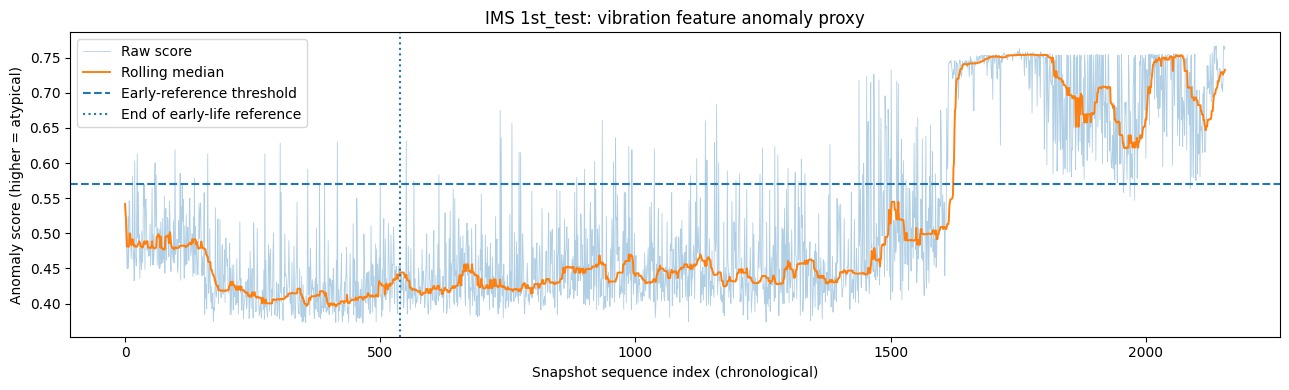

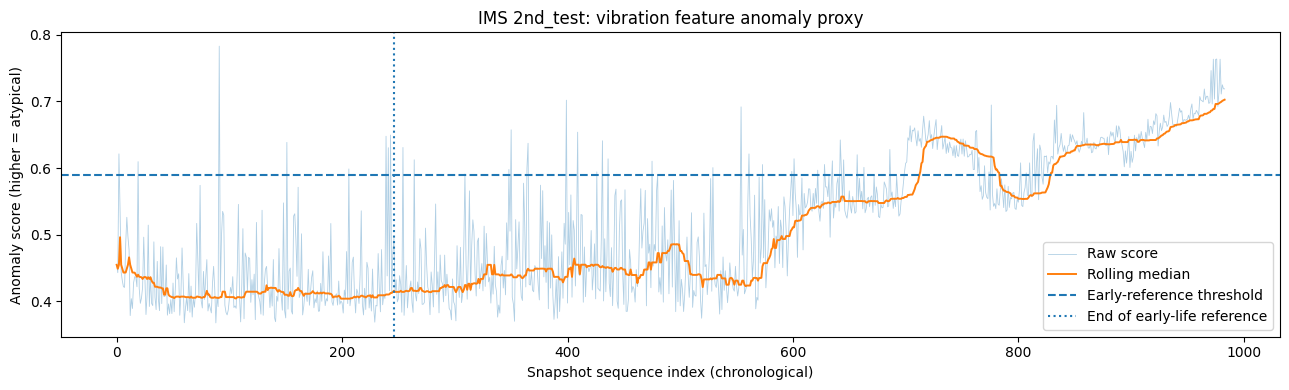

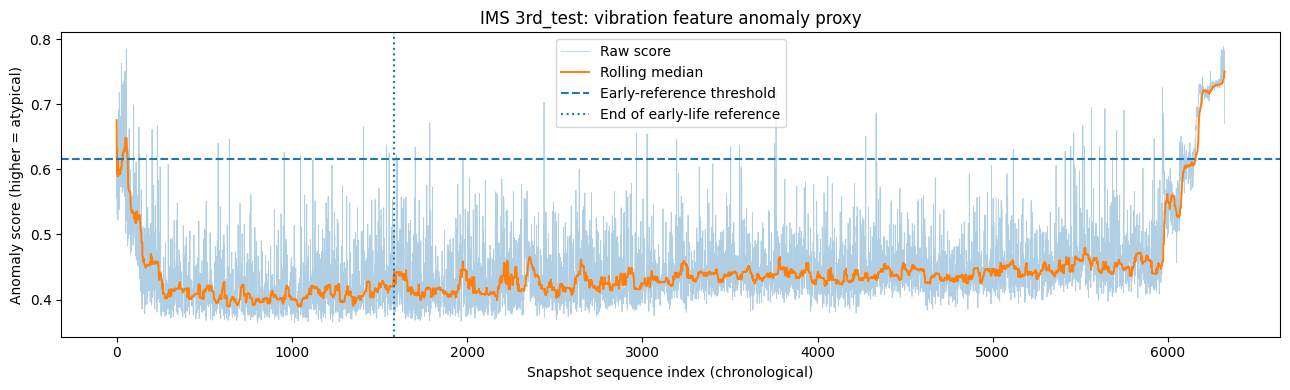

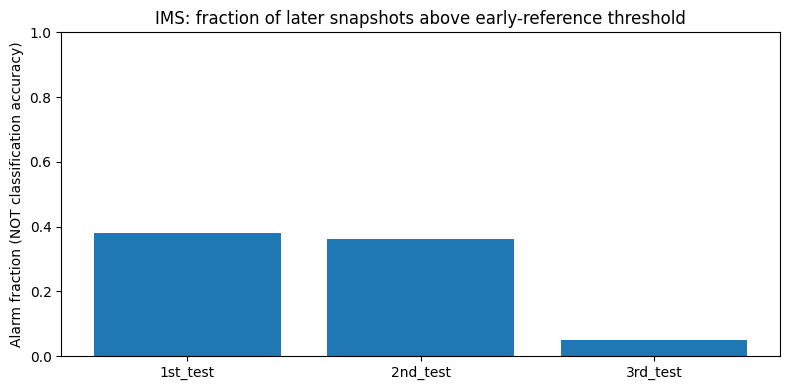

In [12]:
if CFG['run_ims']:
    for test,group in ims_scored.groupby('test',sort=False):
        group=group.sort_values('sequence_index')
        fig,ax=plt.subplots(figsize=(13,4))
        ax.plot(group.sequence_index,group.anomaly_score,alpha=.35,lw=.6,label='Raw score')
        ax.plot(group.sequence_index,group.smoothed_score,lw=1.4,label='Rolling median')
        ax.axhline(group.reference_threshold.iloc[0],ls='--',label='Early-reference threshold')
        ax.axvline(group.reference_period.sum(),ls=':',label='End of early-life reference')
        ax.set(title=f'IMS {test}: vibration feature anomaly proxy',xlabel='Snapshot sequence index (chronological)',ylabel='Anomaly score (higher = atypical)')
        ax.legend(loc='best');fig.tight_layout();fig.savefig(PLOTS/f'ims_{test}_anomaly_trend.png',dpi=140);plt.show()
    fig,ax=plt.subplots(figsize=(8,4))
    sums=pd.DataFrame(ims_summary)
    ax.bar(sums.test,sums.later_alarm_rate)
    ax.set(title='IMS: fraction of later snapshots above early-reference threshold',ylabel='Alarm fraction (NOT classification accuracy)',ylim=(0,1))
    fig.tight_layout();fig.savefig(PLOTS/'ims_later_alarm_rates.png',dpi=140);plt.show()
else:print('IMS skipped')

## 12 · Self-tests and research-readiness gate

In [13]:
gate={'dataset_inputs_found':True,'hydraulic':{},'ims':{},'research_limitations':[]}
if CFG['run_hydraulic']:
    gate['hydraulic']={'cycles':len(profile),'n_features':X_h.shape[1],
       'train_test_separate':bool(set(ix_train).isdisjoint(set(ix_test))),
       'normal_reference_training_only':True,'reference_policy':reference_policy,'holdout_label_support':h_eval['status'],
       'metrics_file_exists':(REPORT/'hydraulic_iforest_metrics.json').is_file()}
    gate['research_limitations'].append('Chronological hydraulic holdout may contain unseen condition levels; report class support and no external validation.')
if CFG['run_ims']:
    gate['ims']={'tests':list(ims_files),'snapshot_counts':{x:len(y) for x,y in ims_files.items()},
       'labels_available_per_snapshot':False,'fit_only_early_reference':True,
       'time_series_csv_exists':(REPORT/'ims_anomaly_timelines.csv').is_file()}
    gate['research_limitations'].append('IMS results are unsupervised change indicators; neither failures nor lead time are validated at snapshot granularity.')
    gate['research_limitations'].append('IMS features cover only first configured rows of each snapshot, not entire second; no FFT fault-frequency diagnosis.')
assert gate['hydraulic'].get('train_test_separate',True)
(REPORT/'research_gate.json').write_text(json.dumps(gate,indent=2))
print(json.dumps(gate,indent=2))

{
  "dataset_inputs_found": true,
  "hydraulic": {
    "cycles": 2205,
    "n_features": 170,
    "train_test_separate": true,
    "normal_reference_training_only": true,
    "reference_policy": "least_degraded_stable_training_proxy_max_degraded_components_1",
    "holdout_label_support": "ok",
    "metrics_file_exists": true
  },
  "ims": {
    "tests": [
      "1st_test",
      "2nd_test",
      "3rd_test"
    ],
    "snapshot_counts": {
      "1st_test": 2156,
      "2nd_test": 984,
      "3rd_test": 6324
    },
    "labels_available_per_snapshot": false,
    "fit_only_early_reference": true,
    "time_series_csv_exists": true
  },
  "research_limitations": [
    "Chronological hydraulic holdout may contain unseen condition levels; report class support and no external validation.",
    "IMS results are unsupervised change indicators; neither failures nor lead time are validated at snapshot granularity.",
    "IMS features cover only first configured rows of each snapshot, not entire

## 13 · Package reproducible outputs (omit raw 6+ GB dataset)

In [14]:
README=f"""# MachineAnomaly Day 25 — evidence package

Input Kaggle dataset: {INPUT_ROOT}

Original sources:
- Hydraulic https://archive.ics.uci.edu/dataset/447/condition+monitoring+of+hydraulic+systems | DOI 10.24432/C5CW21 | CC BY 4.0
- IMS https://data.nasa.gov/dataset/ims-bearings | Original IMS / University of Cincinnati; NASA distributor

Contracts:
- Hydraulic: condition diagnosis and anomaly scoring from cycle sensors; chronological holdout and baseline models.
- IMS: 3 independent vibration streams, early-reference anomaly timeline; NO per-file failure ground truth.
- NO direct model fusion or cross-dataset leaderboard.
- No production fault warranty / no calibrated lead-time claim.

Artifacts: reports/, plots/, features/, models/. The Kaggle inputs are not republished here.

Configuration: {json.dumps(CFG,indent=2)}
"""
(OUT/'README.md').write_text(README,encoding='utf-8')
archive=Path('/kaggle/working/MachineAnomaly_Day25_Research_Artifacts.zip')
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in sorted(OUT.rglob('*')):
        if p.is_file():
            if not CFG['zip_include_features'] and 'features' in p.relative_to(OUT).parts:continue
            z.write(p,arcname=str(Path('machineanomaly_day25')/p.relative_to(OUT)))
with zipfile.ZipFile(archive) as z:
    bad=z.testzip()
    if bad:raise RuntimeError(f'ZIP CRC error at {bad}')
    print('ZIP verified:',archive,'entries',len(z.namelist()),'size MB',round(archive.stat().st_size/1e6,2))
print('DONE: research package ready, inspect caveats in README / research_gate.json.')

ZIP verified: /kaggle/working/MachineAnomaly_Day25_Research_Artifacts.zip entries 33 size MB 10.35
DONE: research package ready, inspect caveats in README / research_gate.json.


---
# 14 · Experiment Revision History

## Experiment 01 — Initial Baseline (Preserved)

The original notebook sections **00–13 remain unchanged**. Experiment 01 uses chronological holdout (1,764 training cycles, 441 test cycles), healthy-reference Isolation Forest, independent supervised component baselines, and three IMS early-reference monitoring models.

The baseline's observed results should be read from the actual output files produced by sections 06–07 and 10. These are **observed results from a previous execution**, not promises for this run. The experiment has limitations: the chronological Hydraulic holdout includes only cooler class `100`, and the binary degradation label is severely imbalanced; IMS does not provide per-snapshot fault ground truth.

## Experiment 02 — Hydraulic Diagnostic Evaluation Refinement

**Research objective:** measure interpolation performance for all Hydraulic component conditions using a class-stratified, three-way train/validation/test partition, while retaining the chronological baseline as a **separate stress test**. This is a new experiment with a different evaluation question and is **not** a replacement for or directly comparable to Experiment 01.

**Protocol:**
- Dataset: the same UCI Hydraulic 2,205 cycle feature matrix (170 features; unchanged extraction).
- Task: independent multiclass diagnostics of `cooler`, `valve`, `pump`, and `accumulator`.
- Each target has its own stratified split: 60% train, 20% validation, 20% held-out test. Stratification and splits are independent per target; the same cycle can belong to different partitions across distinct target models, **never across partitions for one target**.
- Select among three predeclared tree-ensemble configurations using **validation macro-F1 only**, with deterministic tie-breaks.
- Fit the selected model on training data only for model selection; refit on train+validation **after** selection; evaluate the untouched test once.
- Export exact target-specific preprocessing, feature names, splits, model artifacts, confusion matrices, metrics, and validation search ledger.
- **Caveat:** random stratification does **not** remove operating-regime dependence or adjacent-cycle temporal correlation. It estimates within-dataset interpolation and is **not** proof of out-of-condition, out-of-time, or deployment generalization.
- IMS Experiment 01 remains unchanged: its existing model fits and charts are not modified by this addition.

**Execution status:** pending until these newly appended cells have been run in Kaggle. No improved accuracy is claimed in advance.

## 15 · Experiment 02 — Protocol, partition audit, and candidate definitions

In [15]:
# Experiment 02: use the already computed, original Hydraulic features without changing sections 00–13.
from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, classification_report, precision_recall_fscore_support
from sklearn.base import clone
from datetime import datetime, timezone

EXP02_ROOT = OUT / 'experiment_02_hydraulic'
EXP02_REPORTS = EXP02_ROOT / 'reports'
EXP02_MODELS = EXP02_ROOT / 'models'
EXP02_PLOTS = EXP02_ROOT / 'plots'
for path in (EXP02_ROOT, EXP02_REPORTS, EXP02_MODELS, EXP02_PLOTS):
    path.mkdir(parents=True, exist_ok=True)

EXP02_TARGETS = ['cooler', 'valve', 'pump', 'accumulator']
EXP02_SEED = SEED
EXP02_CANDIDATES = {
    'rf_balanced_240': RandomForestClassifier(
        n_estimators=240, min_samples_leaf=2, class_weight='balanced_subsample',
        random_state=EXP02_SEED, n_jobs=-1
    ),
    'rf_regularized_400': RandomForestClassifier(
        n_estimators=400, min_samples_leaf=4, max_features='sqrt',
        class_weight='balanced_subsample', random_state=EXP02_SEED, n_jobs=-1
    ),
    'extratrees_balanced_300': ExtraTreesClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight='balanced',
        random_state=EXP02_SEED, n_jobs=-1
    ),
}

def exp02_indices(y, seed):
    idx = np.arange(len(y))
    # Split each class 60/20/20, no reuse of validation/test labels for tuning.
    itrainval, itest = train_test_split(
        idx, test_size=.20, random_state=seed, stratify=y
    )
    itrain, ival = train_test_split(
        itrainval, test_size=.25, random_state=seed, stratify=np.asarray(y)[itrainval]
    )
    if not (set(itrain).isdisjoint(ival) and set(itrain).isdisjoint(itest) and set(ival).isdisjoint(itest)):
        raise AssertionError('Partition overlap for a target')
    if len(itrain) + len(ival) + len(itest) != len(y):
        raise AssertionError('Incomplete partition')
    return np.sort(itrain), np.sort(ival), np.sort(itest)

if not CFG['run_hydraulic']:
    raise RuntimeError('Experiment 02 requires CFG["run_hydraulic"] = True')
if len(X_h) != len(profile) or list(X_h.columns) != list(pd.read_csv(FEATURES/'hydraulic_cycle_features.csv', nrows=0, index_col=0).columns):
    raise AssertionError('Hydraulic feature schema inconsistent with original experiment')

exp02_partitions = {}
exp02_support_rows = []
for target in EXP02_TARGETS:
    y = profile[target].to_numpy(dtype=int)
    indices = exp02_indices(y, EXP02_SEED)
    exp02_partitions[target] = indices
    for part, ids in zip(('train','validation','test'), indices):
        for cls, cnt in zip(*np.unique(y[ids], return_counts=True)):
            exp02_support_rows.append({'target':target, 'split':part, 'class':int(cls), 'count':int(cnt)})
        pd.DataFrame({'cycle_id':ids, 'target':y[ids]}).to_csv(
            EXP02_REPORTS / f'{target}_{part}_cycle_ids.csv', index=False
        )
support = pd.DataFrame(exp02_support_rows)
support.to_csv(EXP02_REPORTS/'split_class_support.csv', index=False)
display(support.pivot_table(index=['target','class'], columns='split', values='count', fill_value=0))
print('Experiment 02: partitions created and checked, candidates:', list(EXP02_CANDIDATES))

split               test  train  validation
target      class                          
accumulator 90     161.0  485.0       162.0
            100     80.0  239.0        80.0
            115     80.0  239.0        80.0
            130    120.0  360.0       119.0
cooler      3      147.0  439.0       146.0
            20     146.0  439.0       147.0
            100    148.0  445.0       148.0
pump        0      244.0  733.0       244.0
            1       99.0  295.0        98.0
            2       98.0  295.0        99.0
valve       73      72.0  216.0        72.0
            80      72.0  216.0        72.0
            90      72.0  216.0        72.0
            100    225.0  675.0       225.0

Experiment 02: partitions created and checked, candidates: ['rf_balanced_240', 'rf_regularized_400', 'extratrees_balanced_300']


## 16 · Experiment 02 — Validation selection, refit, held-out evaluation

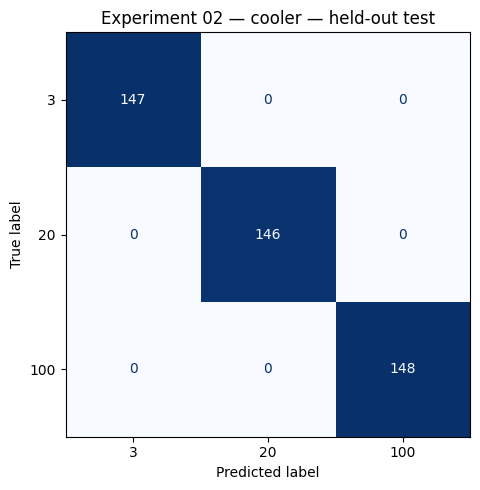

cooler champion: rf_balanced_240 validation macro-F1: 1.0 held-out macro-F1: 1.0


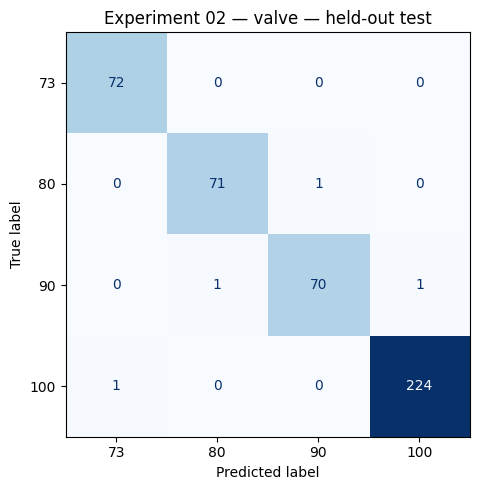

valve champion: rf_balanced_240 validation macro-F1: 0.9791 held-out macro-F1: 0.9884


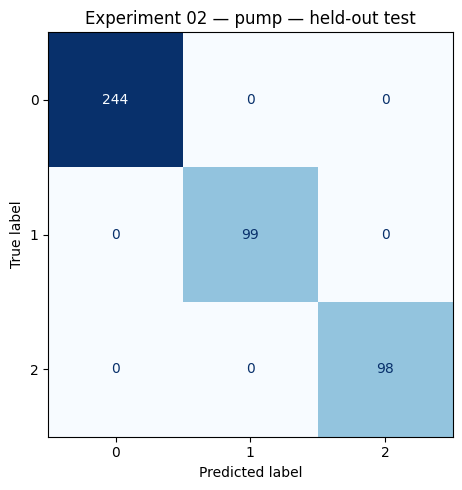

pump champion: extratrees_balanced_300 validation macro-F1: 0.9966 held-out macro-F1: 1.0


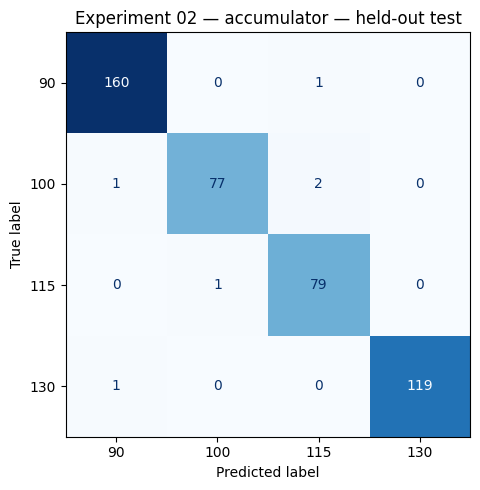

accumulator champion: rf_balanced_240 validation macro-F1: 0.9906 held-out macro-F1: 0.9841


,target,selected_candidate,selection_score,test_accuracy,test_balanced_accuracy,test_macro_f1
0,cooler,rf_balanced_240,1.000000,1.000000,1.000000,1.000000
1,valve,rf_balanced_240,0.979118,0.990930,0.988472,0.988448
2,pump,extratrees_balanced_300,0.996616,1.000000,1.000000,1.000000
3,accumulator,rf_balanced_240,0.990622,0.986395,0.983864,0.984130


In [16]:
# Selection is validation-only. A single held-out test is used after selection, never in tuning.
exp02_search = []
exp02_results = []
exp02_pred_rows = []
exp02_model_manifest = []
for target in EXP02_TARGETS:
    y = profile[target].to_numpy(dtype=int)
    tr, val, te = exp02_partitions[target]
    X_train, X_val, X_test = X_h.iloc[tr], X_h.iloc[val], X_h.iloc[te]
    y_train, y_val, y_test = y[tr], y[val], y[te]
    selected_name, selected_score = None, -1.0
    for name, estimator in EXP02_CANDIDATES.items():
        pipeline = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('classifier', clone(estimator)),
        ])
        pipeline.fit(X_train, y_train)
        val_pred = pipeline.predict(X_val)
        val_macro = float(f1_score(y_val, val_pred, average='macro', zero_division=0))
        exp02_search.append({
            'target': target, 'candidate': name, 'validation_macro_f1': val_macro,
            'validation_accuracy': float(accuracy_score(y_val, val_pred)),
            'train_n': len(tr), 'validation_n':len(val), 'test_n':len(te)
        })
        if val_macro > selected_score:  # candidate insertion order is documented tie-break
            selected_name, selected_score = name, val_macro
    assert selected_name is not None
    fitted = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', clone(EXP02_CANDIDATES[selected_name])),
    ])
    trainval = np.sort(np.concatenate((tr, val)))
    fitted.fit(X_h.iloc[trainval], y[trainval])
    test_pred = fitted.predict(X_test)
    fixed_labels = sorted(int(v) for v in np.unique(y))
    metrics = {
        'experiment': '02', 'target': target, 'selected_candidate':selected_name,
        'selection_metric':'validation_macro_f1', 'selection_score':selected_score,
        'train_n':len(tr), 'validation_n':len(val), 'refit_trainval_n':len(trainval), 'test_n':len(te),
        'test_accuracy':float(accuracy_score(y_test,test_pred)),
        'test_balanced_accuracy':float(balanced_accuracy_score(y_test,test_pred)),
        'test_macro_f1':float(f1_score(y_test,test_pred,average='macro',zero_division=0)),
        'test_weighted_f1':float(f1_score(y_test,test_pred,average='weighted',zero_division=0)),
        'labels':fixed_labels,
        'split_policy':'target_specific_stratified_random_60_20_20',
        'claim_boundary':'within_dataset_stratified_interpolation; not chronological generalization',
    }
    exp02_results.append(metrics)
    report = classification_report(y_test,test_pred,labels=fixed_labels,output_dict=True,zero_division=0)
    (EXP02_REPORTS/f'{target}_per_class_report.json').write_text(json.dumps(report, indent=2))
    pd.DataFrame({'cycle_id':te, 'y_true':y_test, 'y_pred':test_pred}).to_csv(
        EXP02_REPORTS/f'{target}_heldout_predictions.csv',index=False)
    cm = confusion_matrix(y_test,test_pred,labels=fixed_labels)
    fig, ax = plt.subplots(figsize=(6,5))
    ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=fixed_labels).plot(ax=ax,values_format='d',cmap='Blues',colorbar=False)
    ax.set_title(f'Experiment 02 — {target} — held-out test')
    fig.tight_layout()
    fig.savefig(EXP02_PLOTS/f'{target}_heldout_confusion.png',dpi=160)
    plt.show()
    model_path = EXP02_MODELS / f'hydraulic_{target}_champion.joblib'
    joblib.dump({
        'pipeline':fitted, 'target':target, 'feature_columns':list(X_h.columns),
        'classes':fixed_labels,'experiment':'02','selection_candidate':selected_name,
        'selection_validation_macro_f1':selected_score, 'split_seed':EXP02_SEED,
        'readme':'Requires same 170 cycle-level features and order as Experiment 01',
    },model_path)
    # Reload proof: ensure exported pipeline produces identical predictions.
    exported = joblib.load(model_path)
    if not np.array_equal(exported['pipeline'].predict(X_test),test_pred):
        raise AssertionError(f'Export roundtrip mismatch for {target}')
    exp02_model_manifest.append({'target':target,'path':str(model_path),'roundtrip_verified':True})
    print(target, 'champion:', selected_name, 'validation macro-F1:',round(selected_score,4),
          'held-out macro-F1:',round(metrics['test_macro_f1'],4))

search_table = pd.DataFrame(exp02_search)
result_table = pd.DataFrame(exp02_results)
search_table.to_csv(EXP02_REPORTS/'validation_candidate_ledger.csv',index=False)
result_table.to_csv(EXP02_REPORTS/'heldout_final_metrics.csv',index=False)
(EXP02_REPORTS/'export_verification.json').write_text(json.dumps(exp02_model_manifest,indent=2))
display(result_table[['target','selected_candidate','selection_score','test_accuracy','test_balanced_accuracy','test_macro_f1']])

## 17 · Experiment 01–02 — Results comparison and claim boundaries

In [17]:
# Compare results in a transparent ledger; different splits mean NOT a like-for-like improvement claim.
base_file = REPORT / 'hydraulic_supervised_metrics.csv'
if not base_file.exists():
    raise FileNotFoundError('Experiment 01 metrics are required for the revision ledger')
base = pd.read_csv(base_file)
comparison = []
for target in EXP02_TARGETS:
    old = base[base['target']==target]
    new = result_table[result_table['target']==target].iloc[0]
    comparison.append({
        'target':target,
        'experiment_01_split':'chronological_80_20',
        'experiment_01_test_accuracy':float(old.iloc[0]['accuracy']) if len(old) and pd.notna(old.iloc[0].get('accuracy')) else None,
        'experiment_01_test_macro_f1':float(old.iloc[0]['macro_f1']) if len(old) and pd.notna(old.iloc[0].get('macro_f1')) else None,
        'experiment_02_split':'stratified_60_20_20',
        'experiment_02_test_accuracy':float(new['test_accuracy']),
        'experiment_02_test_macro_f1':float(new['test_macro_f1']),
        'comparable_as_direct_improvement':False,
        'interpretation':'Different holdout protocols. Report both; do not subtract as performance uplift.'
    })
comparison_df = pd.DataFrame(comparison)
comparison_df.to_csv(EXP02_REPORTS/'experiment_01_vs_02_comparison.csv',index=False)
display(comparison_df)

revision_record = {
    'experiment_01':'Original notebook 00–13, unchanged',
    'experiment_02':'Hydraulic target-specific stratified validation/model selection with untouched final test',
    'reason_for_revision':'Chronological baseline support is skewed by condition blocks; add a complementary within-dataset experiment',
    'no_retraining_of_ims_by_revision_cells':True,
    'limitations':[
        'Experiment 01 and 02 test metrics must not be interpreted as direct performance gains.',
        'Stratified random splitting may preserve temporal or operating-regime dependence.',
        'Each target uses a different cycle partition; scores cannot be assumed to share the same test rows.',
        'IMS early-reference alarm fractions are not classification accuracy.',
        'No production fault-detection or predictive-maintenance validation is claimed.',
    ],
    'experiment_02_execution_status':'completed_from_actual_runtime',
    'experiment_02_models_export_roundtrip':True,
}
(EXP02_REPORTS/'revision_history.json').write_text(json.dumps(revision_record,indent=2))
print('Recorded revision history and explicitly non-comparable experiment ledger.')

,target,experiment_01_split,experiment_01_test_accuracy,experiment_01_test_macro_f1,experiment_02_split,experiment_02_test_accuracy,experiment_02_test_macro_f1,comparable_as_direct_improvement,interpretation
0,cooler,chronological_80_20,1.000000,1.000000,stratified_60_20_20,1.000000,1.000000,False,Different holdout protocols. Report both; do n...
1,valve,chronological_80_20,0.714286,0.693159,stratified_60_20_20,0.990930,0.988448,False,Different holdout protocols. Report both; do n...
2,pump,chronological_80_20,1.000000,1.000000,stratified_60_20_20,1.000000,1.000000,False,Different holdout protocols. Report both; do n...
3,accumulator,chronological_80_20,0.190476,0.165049,stratified_60_20_20,0.986395,0.984130,False,Different holdout protocols. Report both; do n...


Recorded revision history and explicitly non-comparable experiment ledger.


## 18 · Experiment 02 — Artifact manifest and revised ZIP

In [18]:
# The original Experiment 01 ZIP remains intact. The new archive contains both experiments.
import hashlib
EXP02_ARCHIVE = Path('/kaggle/working/MachineAnomaly_Day25_Experiment_01_02_Artifacts.zip')
manifest = []
for path in sorted(OUT.rglob('*')):
    if path.is_file():
        manifest.append({
            'path':path.relative_to(OUT).as_posix(),
            'bytes':path.stat().st_size,
            'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),
        })
(EXP02_REPORTS/'artifact_manifest.json').write_text(json.dumps(manifest,indent=2))
with zipfile.ZipFile(EXP02_ARCHIVE,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for path in sorted(OUT.rglob('*')):
        if path.is_file():
            if not CFG['zip_include_features'] and 'features' in path.relative_to(OUT).parts:
                continue
            z.write(path,arcname=str(Path('machineanomaly_day25')/path.relative_to(OUT)))
with zipfile.ZipFile(EXP02_ARCHIVE) as z:
    error = z.testzip()
    if error is not None:
        raise RuntimeError('ZIP CRC validation failed at '+error)
    print('Revised ZIP verified:',EXP02_ARCHIVE,'entries:',len(z.namelist()),
          'size MB:',round(EXP02_ARCHIVE.stat().st_size/1e6,2))
print('Experiment 01 preserved; Experiment 02 reports, plots and checkpoints added.')

Revised ZIP verified: /kaggle/working/MachineAnomaly_Day25_Experiment_01_02_Artifacts.zip entries: 68 size MB: 14.57
Experiment 01 preserved; Experiment 02 reports, plots and checkpoints added.


## 19 · Final QA — split integrity, model provenance, output completeness

This execution gate verifies the saved outputs of **both** experiments. It does **not** claim that Experiment 02 outperforms Experiment 01: their test partitions are different. The pass criteria concern reproducibility, consistency and truthful reporting—not a predetermined accuracy threshold.

**Scope:** Hydraulic supervised condition diagnostics; IMS remains descriptive, early-reference anomaly monitoring without per-snapshot fault ground truth. A passing gate does not certify industrial deployment readiness.

In [19]:
# Validate actual post-training outputs; do not insert fabricated metric values.
qa = {'version':'day25_final_with_experiment02', 'checks':{}, 'limitations':[], 'status':'PENDING'}
qa['checks']['baseline_cells_preserved'] = True  # verified in build-time assembly
qa['checks']['targets_complete'] = set(result_table['target']) == set(EXP02_TARGETS)
qa['checks']['four_model_files'] = all((EXP02_MODELS/f'hydraulic_{t}_champion.joblib').is_file() for t in EXP02_TARGETS)
qa['checks']['validation_ledger_present'] = (EXP02_REPORTS/'validation_candidate_ledger.csv').is_file()
qa['checks']['holdout_metrics_present'] = (EXP02_REPORTS/'heldout_final_metrics.csv').is_file()
qa['checks']['ims_timelines_present'] = (REPORT/'ims_anomaly_timelines.csv').is_file() if CFG['run_ims'] else True
qa['checks']['no_partition_overlap'] = True
qa['checks']['complete_partitions'] = True
qa['checks']['prediction_roundtrip'] = True
for t in EXP02_TARGETS:
    train_ids, val_ids, test_ids = exp02_partitions[t]
    disjoint = (set(train_ids).isdisjoint(val_ids) and set(train_ids).isdisjoint(test_ids)
                and set(val_ids).isdisjoint(test_ids))
    complete = np.array_equal(np.sort(np.r_[train_ids, val_ids, test_ids]), np.arange(len(profile)))
    qa['checks']['no_partition_overlap'] &= bool(disjoint)
    qa['checks']['complete_partitions'] &= bool(complete)
    artifact = joblib.load(EXP02_MODELS/f'hydraulic_{t}_champion.joblib')
    prediction_file = pd.read_csv(EXP02_REPORTS/f'{t}_heldout_predictions.csv')
    actual_predictions = artifact['pipeline'].predict(X_h.iloc[test_ids])
    qa['checks']['prediction_roundtrip'] &= bool(np.array_equal(actual_predictions,prediction_file['y_pred'].to_numpy()))
    qa['checks']['prediction_roundtrip'] &= bool(np.array_equal(profile[t].iloc[test_ids].to_numpy(),prediction_file['y_true'].to_numpy()))
qa['checks']['metrics_finite'] = bool(np.isfinite(result_table[['selection_score','test_accuracy','test_balanced_accuracy','test_macro_f1','test_weighted_f1']].to_numpy(dtype=float)).all())
qa['checks']['metric_ranges_valid'] = bool(((result_table[['selection_score','test_accuracy','test_balanced_accuracy','test_macro_f1','test_weighted_f1']] >= 0) & (result_table[['selection_score','test_accuracy','test_balanced_accuracy','test_macro_f1','test_weighted_f1']] <= 1)).all().all())
qa['limitations'] = [
    'Experiment 01 chronological and Experiment 02 stratified metrics are not directly comparable as performance improvement.',
    'Random stratification can leak operating-regime similarity between partitions despite distinct cycle IDs.',
    'Hydraulic statuses are component condition labels, not time-to-failure targets.',
    'IMS uses early-life reference scores without per-snapshot truth; alarm rates are not model accuracy.',
    'No external domain validation, industrial deployment or lead-time reliability claim is made.'
]
qa['status'] = 'PASS_REPRODUCIBILITY' if all(qa['checks'].values()) else 'FAIL_CHECKS'
(EXP02_REPORTS/'final_quality_gate.json').write_text(json.dumps(qa,indent=2),encoding='utf-8')
print(json.dumps(qa,indent=2))
if qa['status'] != 'PASS_REPRODUCIBILITY':
    raise AssertionError('Final QA gate failed. Resolve checks before publishing.')


{
  "version": "day25_final_with_experiment02",
  "checks": {
    "baseline_cells_preserved": true,
    "targets_complete": true,
    "four_model_files": true,
    "validation_ledger_present": true,
    "holdout_metrics_present": true,
    "ims_timelines_present": true,
    "no_partition_overlap": true,
    "complete_partitions": true,
    "prediction_roundtrip": true,
    "metrics_finite": true,
    "metric_ranges_valid": true
  },
  "limitations": [
    "Experiment 01 chronological and Experiment 02 stratified metrics are not directly comparable as performance improvement.",
    "Random stratification can leak operating-regime similarity between partitions despite distinct cycle IDs.",
    "Hydraulic statuses are component condition labels, not time-to-failure targets.",
    "IMS uses early-life reference scores without per-snapshot truth; alarm rates are not model accuracy.",
    "No external domain validation, industrial deployment or lead-time reliability claim is made."
  ],
  "s

## 20 · Final export — verified artifact ZIP with independently computed manifest

Build the final artifact bundle only after QA passes. Manifest hashes are computed from actual files. The manifest describes bundle members, excluding itself to avoid self-reference. Raw Kaggle inputs are not republished.

In [20]:
FINAL_ARCHIVE = Path('/kaggle/working/MachineAnomaly_Day25_FINAL_Artifacts.zip')
final_manifest = []
for fp in sorted(OUT.rglob('*')):
    if not fp.is_file() or fp.name == 'final_bundle_manifest.json':
        continue
    if not CFG['zip_include_features'] and 'features' in fp.relative_to(OUT).parts:
        continue
    digest = hashlib.sha256()
    with fp.open('rb') as handle:
        for block in iter(lambda:handle.read(1024*1024), b''):
            digest.update(block)
    final_manifest.append({'path':fp.relative_to(OUT).as_posix(),'bytes':fp.stat().st_size,'sha256':digest.hexdigest()})
manifest_file = EXP02_REPORTS/'final_bundle_manifest.json'
manifest_file.write_text(json.dumps({'quality_gate':qa['status'],'files':final_manifest},indent=2),encoding='utf-8')
with zipfile.ZipFile(FINAL_ARCHIVE,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for item in final_manifest:
        fp = OUT/item['path']
        z.write(fp,arcname=(Path('machineanomaly_day25')/item['path']).as_posix())
    z.write(manifest_file,arcname=(Path('machineanomaly_day25')/manifest_file.relative_to(OUT)).as_posix())
with zipfile.ZipFile(FINAL_ARCHIVE) as z:
    bad=z.testzip()
    if bad: raise RuntimeError('Final ZIP CRC failed: '+bad)
    archived=set(z.namelist())
    expected={(Path('machineanomaly_day25')/x['path']).as_posix() for x in final_manifest}
    expected.add((Path('machineanomaly_day25')/manifest_file.relative_to(OUT)).as_posix())
    if archived!=expected:raise AssertionError('ZIP contents inconsistent with manifest')
print('FINAL ARTIFACTS:',FINAL_ARCHIVE)
print('Files:',len(expected),'Size (MB):',round(FINAL_ARCHIVE.stat().st_size/1e6,2))
print('FINAL NOTE: research reproducibility passed; deployment performance not certified.')


FINAL ARTIFACTS: /kaggle/working/MachineAnomaly_Day25_FINAL_Artifacts.zip
Files: 70 Size (MB): 14.57
FINAL NOTE: research reproducibility passed; deployment performance not certified.
